In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Flatten, Dense, Dropout)
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# **Load dataset dan eksplorasi gambar**

**Load dataset Fashion-MNIST**

In [ ]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("Training data:", X_train_full.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [ ]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal",
               "Shirt", "Sneaker", "Bag", "Ankle boot"]

**Visualisasi gambar original**

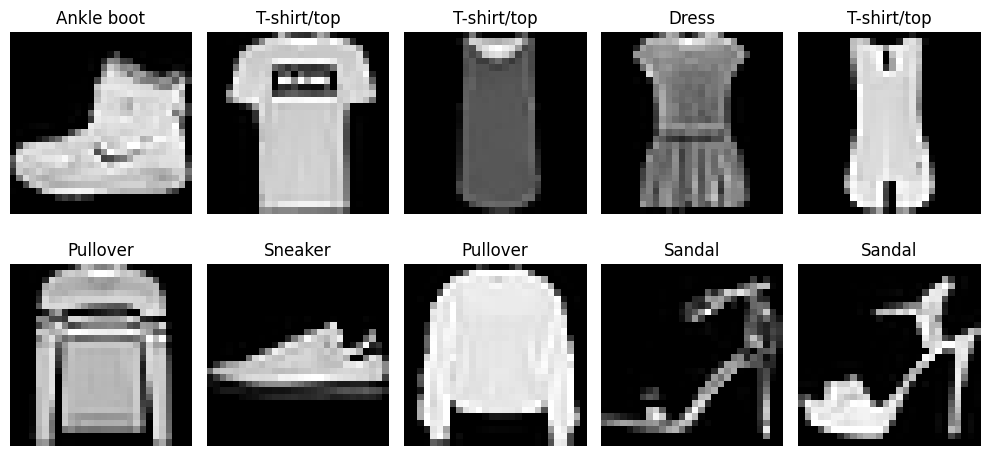

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# **Preprocessing dan reshape**

**Membagi training dan validation**

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (48000, 28, 28)
Validation: (12000, 28, 28)
Testing: (10000, 28, 28)


**Preprocessing gambar**

Normalisasi nilai piksel dari rentang 0–255 menjadi 0–1.

In [ ]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

Tambahkan dimensi channel agar gambar memiliki format (28, 28, 1)

In [ ]:
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training shape:", X_train.shape)

Training shape: (48000, 28, 28, 1)


# **Modelling**

**Membangun model baseline MLP**

In [ ]:
model_baseline = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_baseline.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_baseline.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

**Training model baseline**

In [ ]:
history_baseline = model_baseline.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8160 - loss: 0.5141 - val_accuracy: 0.8420 - val_loss: 0.4273
Epoch 2/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8598 - loss: 0.3802 - val_accuracy: 0.8677 - val_loss: 0.3609
Epoch 3/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8726 - loss: 0.3413 - val_accuracy: 0.8765 - val_loss: 0.3412
Epoch 4/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8807 - loss: 0.3169 - val_accuracy: 0.8835 - val_loss: 0.3218
Epoch 5/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8890 - loss: 0.2965 - val_accuracy: 0.8818 - val_loss: 0.3312
Epoch 6/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8955 - loss: 0.2799 - val_accuracy: 0.8839 - val_loss: 0.3321
Epoch 7/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8985 - loss: 0.2663 - val_accuracy: 0.8832 - val_loss: 0.3311
Epoch 8/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9041 - loss: 0.2541 -

**Visualisasi learning curve**

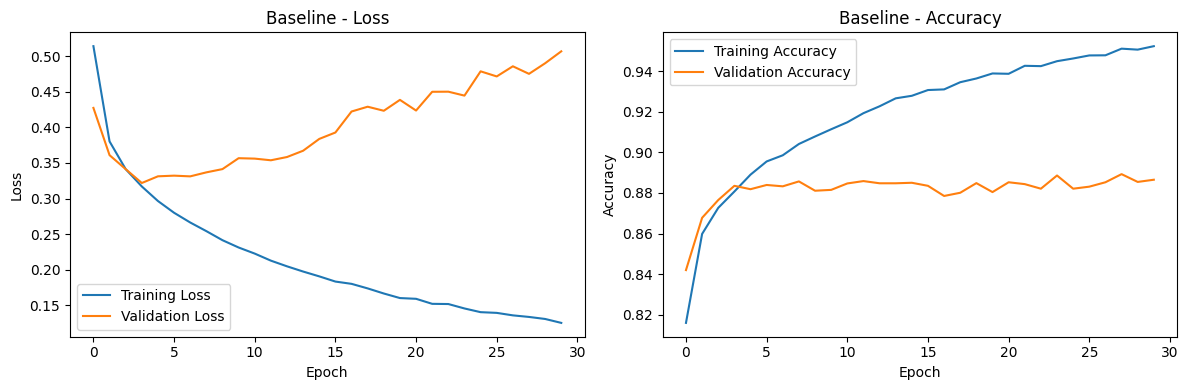

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history["loss"], label="Training Loss")
plt.plot(history_baseline.history["val_loss"], label="Validation Loss")
plt.title("Baseline - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history["accuracy"], label="Training Accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

# **Evaluasi**

**Evaluasi baseline pada data testing**

In [ ]:
y_pred_baseline_prob = model_baseline.predict(X_test, verbose=0)

y_pred_baseline = np.argmax(
    y_pred_baseline_prob,
    axis=1
)

print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.80      0.82      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.71      0.88      0.78      1000
       Dress       0.88      0.89      0.88      1000
        Coat       0.85      0.71      0.77      1000
      Sandal       0.97      0.94      0.96      1000
       Shirt       0.70      0.68      0.69      1000
     Sneaker       0.90      0.98      0.94      1000
         Bag       0.98      0.95      0.96      1000
  Ankle boot       0.97      0.93      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



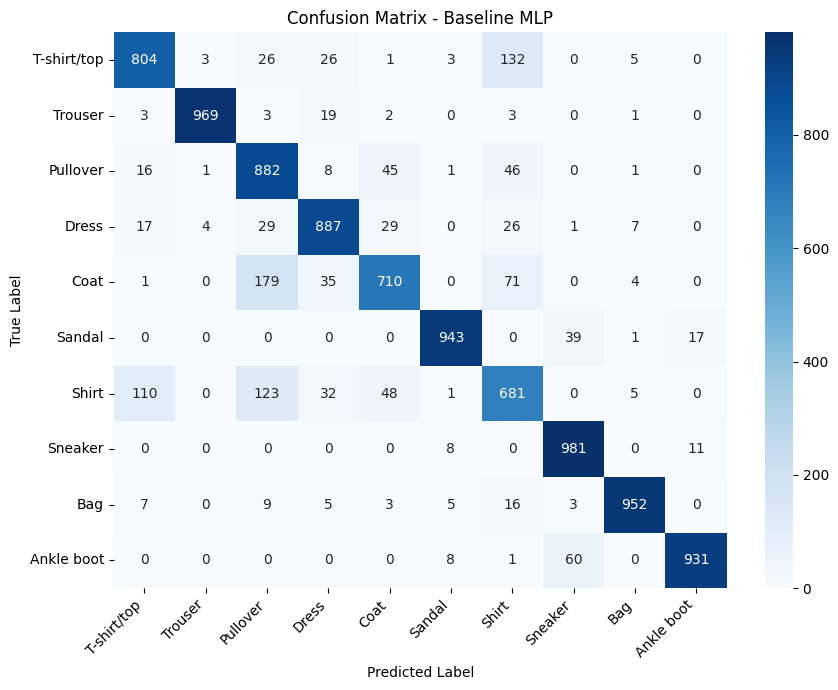

In [ ]:
cm_baseline = confusion_matrix(
    y_test,
    y_pred_baseline
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Baseline MLP")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()